In [7]:
# ============================================================
# 06B.0 — PCA ANALYSIS DATA SETUP
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RANDOM_SEED = 42

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().parent.parent

RECORDING_FEATURE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "acoustic_features_recording.csv"
)

if not RECORDING_FEATURE_PATH.exists():
    raise FileNotFoundError(
        f"Recording-level feature table not found:\n"
        f"{RECORDING_FEATURE_PATH}"
    )

# ------------------------------------------------------------
# 2. Load authoritative recording-level feature table
# ------------------------------------------------------------

recording_features = pd.read_csv(
    RECORDING_FEATURE_PATH
)

# ------------------------------------------------------------
# 3. Reproduce the feature classification used in Notebook 06
# ------------------------------------------------------------

metadata_cols = [
    "recording_id",
    "state",
    "species_id",
    "common_name",
    "scientific_name",
    "original_sample_rate",
    "original_channels",
    "flag_short_duration",
    "flag_low_amplitude",
    "flag_clipping",
    "flag_low_quality",
    "flag_any",
    "flag_bandlimit_incompatible",
    "n_windows",
]

acoustic_cols = [
    c for c in recording_features.columns
    if c not in metadata_cols
]

mean_cols = [
    c for c in acoustic_cols
    if c.endswith("_mean")
]

# ------------------------------------------------------------
# 4. Authoritative primary PCA matrix
# ------------------------------------------------------------

PRIMARY_FEATURES = mean_cols.copy()

X_primary = recording_features[
    PRIMARY_FEATURES
].copy()

# ------------------------------------------------------------
# 5. Validation
# ------------------------------------------------------------

assert recording_features.shape[0] == 275
assert len(PRIMARY_FEATURES) == 50
assert X_primary.shape == (275, 50)

assert X_primary.isna().sum().sum() == 0
assert np.isfinite(
    X_primary.to_numpy()
).all()

print("=" * 70)
print("6B PCA DATA SETUP")
print("=" * 70)

print("Recording feature table:", recording_features.shape)
print("Primary PCA matrix:", X_primary.shape)

print("\nMissing values:", X_primary.isna().sum().sum())
print(
    "Non-finite values:",
    (~np.isfinite(X_primary.to_numpy())).sum()
)

print("\nPrimary feature count:", len(PRIMARY_FEATURES))

print("\nFirst 10 primary features:")
for feature in PRIMARY_FEATURES[:10]:
    print(" -", feature)

print("\nSetup validated.")

6B PCA DATA SETUP
Recording feature table: (275, 114)
Primary PCA matrix: (275, 50)

Missing values: 0
Non-finite values: 0

Primary feature count: 50

First 10 primary features:
 - aci_mean
 - adi_mean
 - bioacoustic_index_mean
 - ndsi_mean
 - ndsi_ratio_ba_mean
 - anthropophony_mean
 - biophony_mean
 - spectral_entropy_eas_mean
 - spectral_entropy_ecu_mean
 - spectral_entropy_ecv_mean

Setup validated.


In [8]:
# ============================================================
# 06B.1 — PCA REPRESENTATION DEFINITIONS
# ============================================================

# Primary analysis matrix:
# one row = one recording
# columns = 50 recording-level mean acoustic features

X_baseline = X_primary.copy()
X_transformed = X_primary.copy()

# ------------------------------------------------------------
# Candidate distribution-adjusting transformations
# ------------------------------------------------------------
#
# These transformations are applied only to features that are:
#   1. strictly positive, and
#   2. strongly right-skewed based on the 6A/6 main audit.
#
# NDSI ratio is handled with log1p because values can approach 0.
# The remaining selected variables use natural log.
# ------------------------------------------------------------

LOG1P_FEATURES = [
    "ndsi_ratio_ba_mean",
]

LOG_FEATURES = [
    "biophony_mean",
    "anthropophony_mean",
    "bioacoustic_index_mean",
    "rms_mean_mean",
    "spectral_entropy_eps_kurt_mean",
    "spectral_entropy_eps_skew_mean",
]

# ------------------------------------------------------------
# Apply transformations
# ------------------------------------------------------------

for feature in LOG1P_FEATURES:

    assert (X_transformed[feature] >= 0).all(), (
        f"{feature} contains negative values; "
        "log1p transformation is invalid."
    )

    X_transformed[feature] = np.log1p(
        X_transformed[feature]
    )


for feature in LOG_FEATURES:

    assert (X_transformed[feature] > 0).all(), (
        f"{feature} contains non-positive values; "
        "log transformation is invalid."
    )

    X_transformed[feature] = np.log(
        X_transformed[feature]
    )

# ------------------------------------------------------------
# Structural validation
# ------------------------------------------------------------

assert X_baseline.shape == X_transformed.shape

assert X_baseline.index.equals(
    X_transformed.index
)

assert X_baseline.columns.tolist() == (
    X_transformed.columns.tolist()
)

assert np.isfinite(
    X_baseline.to_numpy()
).all()

assert np.isfinite(
    X_transformed.to_numpy()
).all()

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 70)
print("PCA REPRESENTATION DEFINITIONS")
print("=" * 70)

print(
    "Recordings:",
    X_baseline.shape[0]
)

print(
    "Features:",
    X_baseline.shape[1]
)

print("\nBaseline representation:")
print(
    "  Raw features → StandardScaler → PCA"
)

print("\nDistribution-adjusted representation:")
print(
    "  Selected log/log1p transformations"
)
print(
    "  → StandardScaler → PCA"
)

print("\nlog1p features:")
for feature in LOG1P_FEATURES:
    print("  -", feature)

print("\nlog features:")
for feature in LOG_FEATURES:
    print("  -", feature)

print("\nValidation:")
print(
    "  Same observations:",
    X_baseline.index.equals(X_transformed.index)
)

print(
    "  Same features:",
    X_baseline.columns.tolist()
    == X_transformed.columns.tolist()
)

print(
    "  Baseline finite:",
    np.isfinite(X_baseline.to_numpy()).all()
)

print(
    "  Transformed finite:",
    np.isfinite(X_transformed.to_numpy()).all()
)

PCA REPRESENTATION DEFINITIONS
Recordings: 275
Features: 50

Baseline representation:
  Raw features → StandardScaler → PCA

Distribution-adjusted representation:
  Selected log/log1p transformations
  → StandardScaler → PCA

log1p features:
  - ndsi_ratio_ba_mean

log features:
  - biophony_mean
  - anthropophony_mean
  - bioacoustic_index_mean
  - rms_mean_mean
  - spectral_entropy_eps_kurt_mean
  - spectral_entropy_eps_skew_mean

Validation:
  Same observations: True
  Same features: True
  Baseline finite: True
  Transformed finite: True


In [9]:
# ============================================================
# 06B.2 — BASELINE vs DISTRIBUTION-ADJUSTED PCA COMPARISON
# ============================================================

# ------------------------------------------------------------
# 1. Standardize each representation
# ------------------------------------------------------------

scaler_baseline = StandardScaler()
scaler_transformed = StandardScaler()

X_baseline_scaled = scaler_baseline.fit_transform(
    X_baseline
)

X_transformed_scaled = scaler_transformed.fit_transform(
    X_transformed
)

# ------------------------------------------------------------
# 2. Fit full PCA to both representations
# ------------------------------------------------------------

pca_baseline = PCA(
    random_state=RANDOM_SEED
)

pca_transformed = PCA(
    random_state=RANDOM_SEED
)

Z_baseline = pca_baseline.fit_transform(
    X_baseline_scaled
)

Z_transformed = pca_transformed.fit_transform(
    X_transformed_scaled
)

# ------------------------------------------------------------
# 3. Explained variance comparison
# ------------------------------------------------------------

variance_comparison = pd.DataFrame({
    "component": np.arange(
        1,
        len(pca_baseline.explained_variance_ratio_) + 1
    ),
    "baseline": (
        pca_baseline.explained_variance_ratio_
    ),
    "distribution_adjusted": (
        pca_transformed.explained_variance_ratio_
    ),
})

variance_comparison["baseline_cumulative"] = (
    variance_comparison["baseline"].cumsum()
)

variance_comparison[
    "distribution_adjusted_cumulative"
] = (
    variance_comparison[
        "distribution_adjusted"
    ].cumsum()
)

print("=" * 70)
print("PCA EXPLAINED VARIANCE COMPARISON")
print("=" * 70)

display(
    variance_comparison
    .head(10)
    .round(4)
)

# ------------------------------------------------------------
# 4. Cumulative variance at key dimensions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CUMULATIVE EXPLAINED VARIANCE")
print("=" * 70)

for k in [1, 2, 3, 5, 10]:

    baseline_value = (
        variance_comparison
        .loc[k - 1, "baseline_cumulative"]
    )

    transformed_value = (
        variance_comparison
        .loc[
            k - 1,
            "distribution_adjusted_cumulative"
        ]
    )

    print(
        f"PC1–PC{k}: "
        f"baseline = {baseline_value:.3f}, "
        f"distribution-adjusted = "
        f"{transformed_value:.3f}"
    )

# ------------------------------------------------------------
# 5. Loading matrices
# ------------------------------------------------------------

loading_baseline = pd.DataFrame(
    pca_baseline.components_.T,
    index=PRIMARY_FEATURES,
    columns=[
        f"PC{i}"
        for i in range(
            1,
            len(PRIMARY_FEATURES) + 1
        )
    ],
)

loading_transformed = pd.DataFrame(
    pca_transformed.components_.T,
    index=PRIMARY_FEATURES,
    columns=[
        f"PC{i}"
        for i in range(
            1,
            len(PRIMARY_FEATURES) + 1
        )
    ],
)

# ------------------------------------------------------------
# 6. Compare loading structure
#
# PCA signs are arbitrary, so compare absolute loadings.
# ------------------------------------------------------------

loading_correlation = {}

for pc in range(5):

    baseline_abs = (
        loading_baseline.iloc[:, pc]
        .abs()
    )

    transformed_abs = (
        loading_transformed.iloc[:, pc]
        .abs()
    )

    loading_correlation[
        f"PC{pc + 1}"
    ] = baseline_abs.corr(
        transformed_abs
    )

print("\n" + "=" * 70)
print("ABSOLUTE LOADING CORRELATION")
print("=" * 70)

display(
    pd.Series(
        loading_correlation,
        name="correlation"
    )
    .to_frame()
    .round(4)
)

# ------------------------------------------------------------
# 7. Compare top variables for each component
# ------------------------------------------------------------

for pc in range(5):

    pc_name = f"PC{pc + 1}"

    print("\n" + "=" * 70)
    print(pc_name)
    print("=" * 70)

    comparison = pd.DataFrame({
        "baseline_abs_loading":
            loading_baseline[pc_name].abs(),

        "distribution_adjusted_abs_loading":
            loading_transformed[pc_name].abs(),
    })

    comparison["absolute_difference"] = (
        comparison[
            "baseline_abs_loading"
        ]
        -
        comparison[
            "distribution_adjusted_abs_loading"
        ]
    ).abs()

    print("\nTop baseline variables:")

    display(
        comparison
        .sort_values(
            "baseline_abs_loading",
            ascending=False
        )
        .head(8)
        .round(4)
    )

    print("\nTop distribution-adjusted variables:")

    display(
        comparison
        .sort_values(
            "distribution_adjusted_abs_loading",
            ascending=False
        )
        .head(8)
        .round(4)
    )

PCA EXPLAINED VARIANCE COMPARISON


,component,baseline,distribution_adjusted,baseline_cumulative,distribution_adjusted_cumulative
0,1,0.2095,0.2167,0.2095,0.2167
1,2,0.1219,0.1384,0.3315,0.3552
2,3,0.0678,0.0756,0.3993,0.4308
3,4,0.0604,0.0638,0.4597,0.4946
4,5,0.0546,0.0565,0.5143,0.5511
5,6,0.0486,0.0486,0.5629,0.5998
6,7,0.0426,0.0396,0.6055,0.6393
7,8,0.0383,0.0378,0.6438,0.6771
8,9,0.0339,0.0331,0.6776,0.7102
9,10,0.0280,0.0279,0.7057,0.7382



CUMULATIVE EXPLAINED VARIANCE
PC1–PC1: baseline = 0.210, distribution-adjusted = 0.217
PC1–PC2: baseline = 0.331, distribution-adjusted = 0.355
PC1–PC3: baseline = 0.399, distribution-adjusted = 0.431
PC1–PC5: baseline = 0.514, distribution-adjusted = 0.551
PC1–PC10: baseline = 0.706, distribution-adjusted = 0.738

ABSOLUTE LOADING CORRELATION


,correlation
PC1,0.9770
PC2,0.9216
PC3,0.8349
PC4,0.8217
PC5,0.8095



PC1

Top baseline variables:


...

,baseline_abs_loading,distribution_adjusted_abs_loading,absolute_difference
spectral_entropy_ecv_mean,0.3344,0.4164,0.0820
spectral_entropy_eas_mean,0.2918,0.3844,0.0926
spectral_entropy_ecu_mean,0.2697,0.3635,0.0938
adi_mean,0.1914,0.2441,0.0527
zcr_mean_mean,0.2513,0.1928,0.0585
spectral_centroid_mean_mean,0.2211,0.1926,0.0285
biophony_mean,0.0963,0.1862,0.0899
ndsi_mean,0.2300,0.1814,0.0485



PC5

Top baseline variables:


,baseline_abs_loading,distribution_adjusted_abs_loading,absolute_difference
rms_std_mean,0.3575,0.2488,0.1087
rms_mean_mean,0.3182,0.2275,0.0907
anthropophony_mean,0.3125,0.2774,0.0351
spectral_bandwidth_mean_mean,0.2646,0.2923,0.0277
bioacoustic_index_mean,0.2567,0.2607,0.0040
biophony_mean,0.2546,0.1337,0.1208
mfcc_03_mean,0.2273,0.2670,0.0397
spectral_rolloff_std_mean,0.2215,0.3639,0.1423



Top distribution-adjusted variables:


,baseline_abs_loading,distribution_adjusted_abs_loading,absolute_difference
spectral_rolloff_std_mean,0.2215,0.3639,0.1423
spectral_bandwidth_mean_mean,0.2646,0.2923,0.0277
spectral_bandwidth_std_mean,0.1891,0.2809,0.0918
spectral_centroid_std_mean,0.1832,0.2793,0.0962
anthropophony_mean,0.3125,0.2774,0.0351
mfcc_03_mean,0.2273,0.2670,0.0397
bioacoustic_index_mean,0.2567,0.2607,0.0040
rms_std_mean,0.3575,0.2488,0.1087


In [10]:
# ============================================================
# 06B.3 — TRANSFORMATION EFFECT ON DISTRIBUTIONS
# ============================================================

distribution_comparison = pd.DataFrame({
    "feature": PRIMARY_FEATURES,
    "baseline_skew": [
        X_baseline[c].skew()
        for c in PRIMARY_FEATURES
    ],
    "transformed_skew": [
        X_transformed[c].skew()
        for c in PRIMARY_FEATURES
    ],
})

distribution_comparison["absolute_skew_reduction"] = (
    distribution_comparison["baseline_skew"].abs()
    - distribution_comparison["transformed_skew"].abs()
)

distribution_comparison["transformed"] = (
    distribution_comparison["feature"].isin(
        LOG1P_FEATURES + LOG_FEATURES
    )
)

print("=" * 70)
print("EFFECT OF TRANSFORMATIONS ON SKEWNESS")
print("=" * 70)

print("\nSelected transformed features:")

display(
    distribution_comparison[
        distribution_comparison["transformed"]
    ]
    .sort_values(
        "absolute_skew_reduction",
        ascending=False
    )
    .round(4)
)

print("\nLargest remaining absolute skew:")

display(
    distribution_comparison
    .sort_values(
        "transformed_skew",
        key=lambda x: x.abs(),
        ascending=False
    )
    .head(15)
    .round(4)
)

print("\nSummary:")
print(
    "Mean absolute skew — baseline:",
    round(
        distribution_comparison["baseline_skew"]
        .abs()
        .mean(),
        3
    )
)

print(
    "Mean absolute skew — transformed:",
    round(
        distribution_comparison["transformed_skew"]
        .abs()
        .mean(),
        3
    )
)

EFFECT OF TRANSFORMATIONS ON SKEWNESS

Selected transformed features:


,feature,baseline_skew,transformed_skew,absolute_skew_reduction,transformed
4,ndsi_ratio_ba_mean,16.0770,1.6286,14.4485,True
6,biophony_mean,6.0546,-0.7845,5.2701,True
11,spectral_entropy_eps_kurt_mean,5.1252,0.5877,4.5375,True
5,anthropophony_mean,4.8516,-0.3670,4.4846,True
2,bioacoustic_index_mean,4.4555,0.1425,4.3130,True
14,rms_mean_mean,3.5972,-0.0452,3.5520,True
12,spectral_entropy_eps_skew_mean,2.8201,0.5856,2.2345,True



Largest remaining absolute skew:


,feature,baseline_skew,transformed_skew,absolute_skew_reduction,transformed
48,mfcc_13_mean,2.5818,2.5818,0.0000,False
4,ndsi_ratio_ba_mean,16.0770,1.6286,14.4485,True
47,mfcc_12_within_std_mean,1.5785,1.5785,0.0000,False
15,rms_std_mean,1.5368,1.5368,0.0000,False
49,mfcc_13_within_std_mean,1.4931,1.4931,0.0000,False
45,mfcc_11_within_std_mean,1.4717,1.4717,0.0000,False
17,zcr_std_mean,1.4532,1.4532,0.0000,False
41,mfcc_09_within_std_mean,1.4134,1.4134,0.0000,False
19,spectral_centroid_std_mean,1.3558,1.3558,0.0000,False
37,mfcc_07_within_std_mean,1.2743,1.2743,0.0000,False



Summary:
Mean absolute skew — baseline: 1.582
Mean absolute skew — transformed: 0.806


In [11]:
# ============================================================
# 06B.4 — LOCK PRIMARY PCA REPRESENTATION
# ============================================================

# ------------------------------------------------------------
# Primary representation
# ------------------------------------------------------------
#
# Based on:
#   1. substantial reduction in feature skewness
#   2. preservation of broad PCA loading structure
#   3. improved concentration of explained variance
#
# The distribution-adjusted representation is the primary PCA
# analysis. The raw-standardized representation is retained as
# a sensitivity analysis.
# ------------------------------------------------------------

X_pca_primary = X_transformed.copy()

X_pca_sensitivity = X_baseline.copy()

# ------------------------------------------------------------
# Standardize
# ------------------------------------------------------------

scaler_primary = StandardScaler()
scaler_sensitivity = StandardScaler()

X_pca_primary_scaled = (
    scaler_primary.fit_transform(
        X_pca_primary
    )
)

X_pca_sensitivity_scaled = (
    scaler_sensitivity.fit_transform(
        X_pca_sensitivity
    )
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert X_pca_primary.shape == (275, 50)
assert X_pca_sensitivity.shape == (275, 50)

assert np.isfinite(
    X_pca_primary_scaled
).all()

assert np.isfinite(
    X_pca_sensitivity_scaled
).all()

# StandardScaler should produce approximately
# zero mean and unit variance for every feature.

assert np.allclose(
    X_pca_primary_scaled.mean(axis=0),
    0,
    atol=1e-10
)

assert np.allclose(
    X_pca_primary_scaled.std(axis=0),
    1,
    atol=1e-10
)

print("=" * 70)
print("PRIMARY PCA REPRESENTATION LOCKED")
print("=" * 70)

print("Primary representation:")
print(
    "  Distribution-adjusted features"
    " → StandardScaler → PCA"
)

print("\nSensitivity representation:")
print(
    "  Raw features"
    " → StandardScaler → PCA"
)

print("\nPrimary matrix:")
print(
    "  Shape:",
    X_pca_primary.shape
)

print("\nSensitivity matrix:")
print(
    "  Shape:",
    X_pca_sensitivity.shape
)

print("\nStandardization validated:")
print("  Primary mean ≈ 0: True")
print("  Primary std ≈ 1: True")

PRIMARY PCA REPRESENTATION LOCKED
Primary representation:
  Distribution-adjusted features → StandardScaler → PCA

Sensitivity representation:
  Raw features → StandardScaler → PCA

Primary matrix:
  Shape: (275, 50)

Sensitivity matrix:
  Shape: (275, 50)

Standardization validated:
  Primary mean ≈ 0: True
  Primary std ≈ 1: True


In [12]:
# ============================================================
# 06B.5 — PRIMARY PCA FIT + EXPLAINED VARIANCE
# ============================================================

# ------------------------------------------------------------
# 1. Fit PCA on the locked primary representation
# ------------------------------------------------------------

pca_primary = PCA(
    random_state=RANDOM_SEED
)

Z_primary = pca_primary.fit_transform(
    X_pca_primary_scaled
)

# ------------------------------------------------------------
# 2. Explained variance table
# ------------------------------------------------------------

pca_variance = pd.DataFrame({
    "component": np.arange(
        1,
        len(pca_primary.explained_variance_ratio_) + 1
    ),
    "explained_variance_ratio":
        pca_primary.explained_variance_ratio_,
    "cumulative_variance":
        np.cumsum(
            pca_primary.explained_variance_ratio_
        ),
})

print("=" * 70)
print("PRIMARY PCA — EXPLAINED VARIANCE")
print("=" * 70)

display(
    pca_variance
    .head(10)
    .round(4)
)

# ------------------------------------------------------------
# 3. Key variance thresholds
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VARIANCE THRESHOLDS")
print("=" * 70)

for threshold in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]:

    n_components = (
        np.argmax(
            pca_variance[
                "cumulative_variance"
            ].to_numpy()
            >= threshold
        )
        + 1
    )

    print(
        f"{threshold:.0%} variance:",
        n_components,
        "components"
    )

# ------------------------------------------------------------
# 4. Kaiser-style reference
# ------------------------------------------------------------
#
# Because the input was standardized, each original variable
# has variance approximately 1. Therefore eigenvalue > 1
# corresponds to explaining more variance than one standardized
# input variable.
# ------------------------------------------------------------

eigenvalues = pca_primary.explained_variance_

print("\n" + "=" * 70)
print("EIGENVALUES")
print("=" * 70)

print(
    "Components with eigenvalue > 1:",
    (eigenvalues > 1).sum()
)

display(
    pd.DataFrame({
        "component": np.arange(
            1,
            len(eigenvalues) + 1
        ),
        "eigenvalue": eigenvalues
    })
    .head(10)
    .round(4)
)

PRIMARY PCA — EXPLAINED VARIANCE


,component,explained_variance_ratio,cumulative_variance
0,1,0.2167,0.2167
1,2,0.1384,0.3552
2,3,0.0756,0.4308
3,4,0.0638,0.4946
4,5,0.0565,0.5511
5,6,0.0486,0.5998
6,7,0.0396,0.6393
7,8,0.0378,0.6771
8,9,0.0331,0.7102
9,10,0.0279,0.7382



VARIANCE THRESHOLDS
50% variance: 5 components
60% variance: 7 components
70% variance: 9 components
80% variance: 13 components
90% variance: 20 components
95% variance: 27 components

EIGENVALUES
Components with eigenvalue > 1: 12


,component,eigenvalue
0,1,10.8754
1,2,6.9471
2,3,3.7960
3,4,3.2018
4,5,2.8372
5,6,2.4411
6,7,1.9853
7,8,1.8966
8,9,1.6610
9,10,1.4013


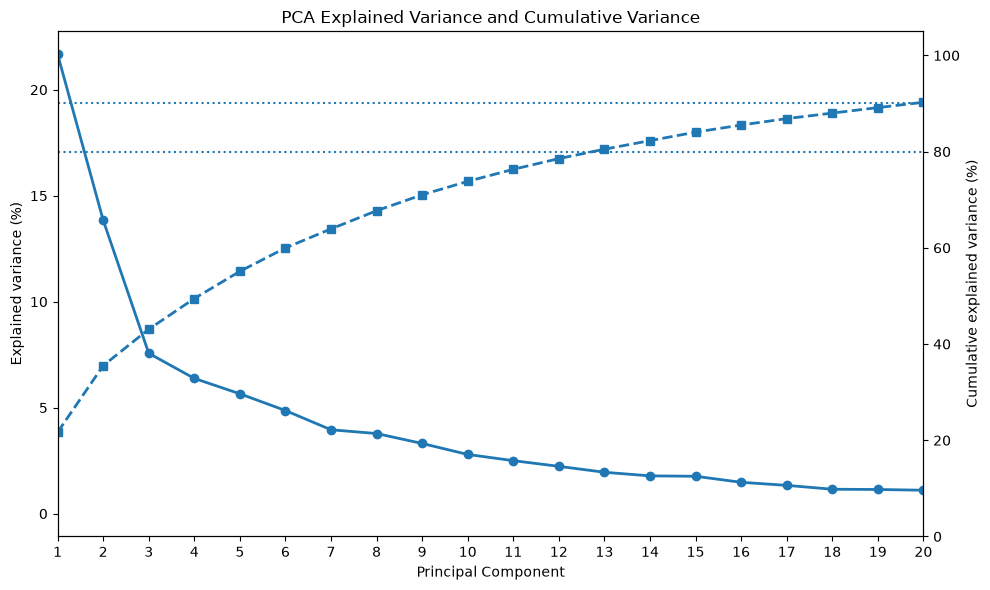

In [14]:
# ============================================================
# 06B.6 — PCA SCREE + CUMULATIVE VARIANCE VISUALIZATION
# ============================================================
import matplotlib.pyplot as plt
fig, ax1 = plt.subplots(figsize=(10, 6))

components = pca_variance["component"]
variance = pca_variance["explained_variance_ratio"] * 100
cumulative = pca_variance["cumulative_variance"] * 100

# Scree plot
ax1.plot(
    components,
    variance,
    marker="o",
    linewidth=2,
    label="Individual explained variance"
)

ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained variance (%)")
ax1.set_title(
    "PCA Explained Variance and Cumulative Variance"
)

# Cumulative variance
ax2 = ax1.twinx()

ax2.plot(
    components,
    cumulative,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Cumulative explained variance"
)

ax2.set_ylabel("Cumulative explained variance (%)")
ax2.set_ylim(0, 105)

# Reference line at 80%
ax2.axhline(
    80,
    linestyle=":",
    linewidth=1.5
)

# Reference line at 90%
ax2.axhline(
    90,
    linestyle=":",
    linewidth=1.5
)

ax1.set_xlim(1, 20)
ax1.set_xticks(range(1, 21))

fig.tight_layout()

plt.show()

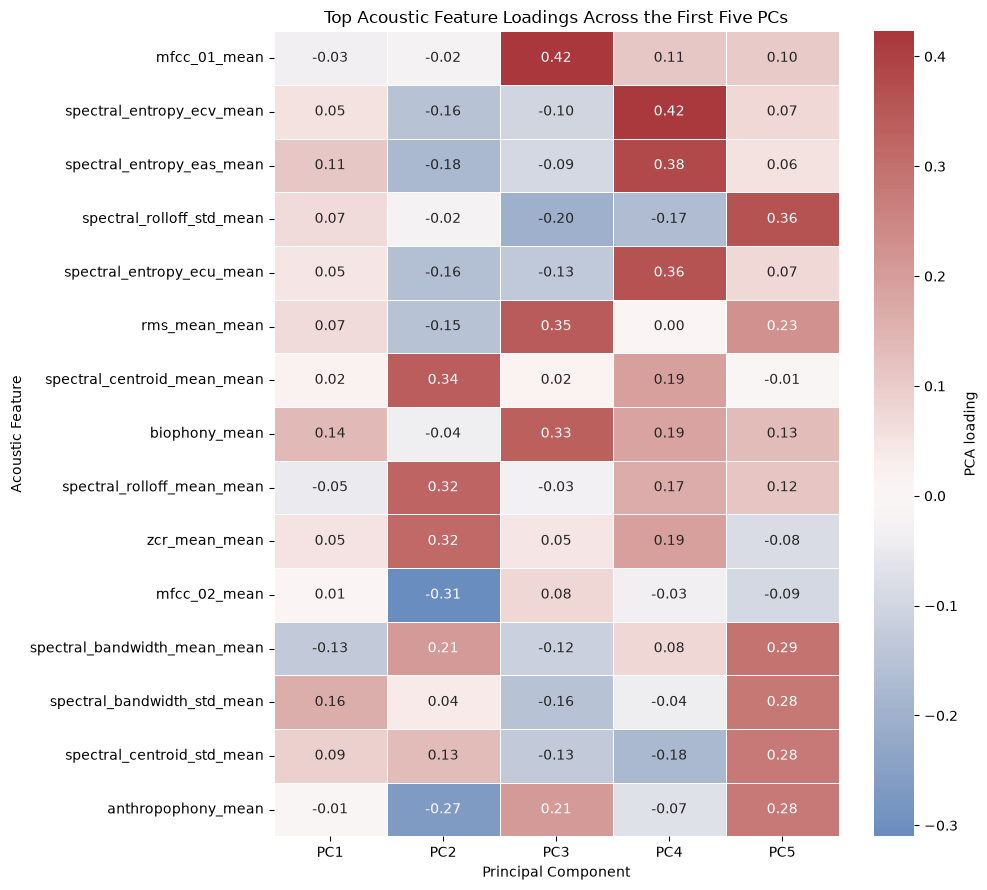

TOP PCA LOADING FEATURES


,PC1,PC2,PC3,PC4,PC5
mfcc_01_mean,-0.0332,-0.0240,0.4228,0.1105,0.1033
spectral_entropy_ecv_mean,0.0545,-0.1553,-0.0986,0.4164,0.0749
spectral_entropy_eas_mean,0.1084,-0.1803,-0.0940,0.3844,0.0563
spectral_rolloff_std_mean,0.0699,-0.0249,-0.2028,-0.1681,0.3639
spectral_entropy_ecu_mean,0.0482,-0.1602,-0.1340,0.3635,0.0743
rms_mean_mean,0.0694,-0.1548,0.3454,0.0005,0.2275
spectral_centroid_mean_mean,0.0188,0.3399,0.0158,0.1926,-0.0119
biophony_mean,0.1374,-0.0371,0.3314,0.1862,0.1337
spectral_rolloff_mean_mean,-0.0483,0.3239,-0.0313,0.1661,0.1152
zcr_mean_mean,0.0534,0.3167,0.0492,0.1928,-0.0837


In [16]:
# ============================================================
# 06B.7 — PCA LOADING HEATMAP
# ============================================================
import seaborn as sns
# ------------------------------------------------------------
# 1. Create loading matrix for first five PCs
# ------------------------------------------------------------

loading_matrix = pd.DataFrame(
    pca_primary.components_[:5].T,
    index=PRIMARY_FEATURES,
    columns=[
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
    ],
)

# ------------------------------------------------------------
# 2. Select the most influential variables
#
# We select the top 15 variables based on their maximum
# absolute loading across the first five components.
# ------------------------------------------------------------

loading_matrix["max_abs_loading"] = (
    loading_matrix.abs().max(axis=1)
)

top_loading_features = (
    loading_matrix
    .sort_values(
        "max_abs_loading",
        ascending=False
    )
    .head(15)
    .index
)

loading_plot = (
    loading_matrix
    .loc[top_loading_features, [
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
    ]]
)

# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 9))

sns.heatmap(
    loading_plot,
    center=0,
    cmap="vlag",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={
        "label": "PCA loading"
    }
)

plt.title(
    "Top Acoustic Feature Loadings Across the First Five PCs"
)

plt.xlabel("Principal Component")
plt.ylabel("Acoustic Feature")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 4. Print the underlying values for interpretation
# ------------------------------------------------------------

print("=" * 70)
print("TOP PCA LOADING FEATURES")
print("=" * 70)

display(
    loading_plot
    .round(4)
)

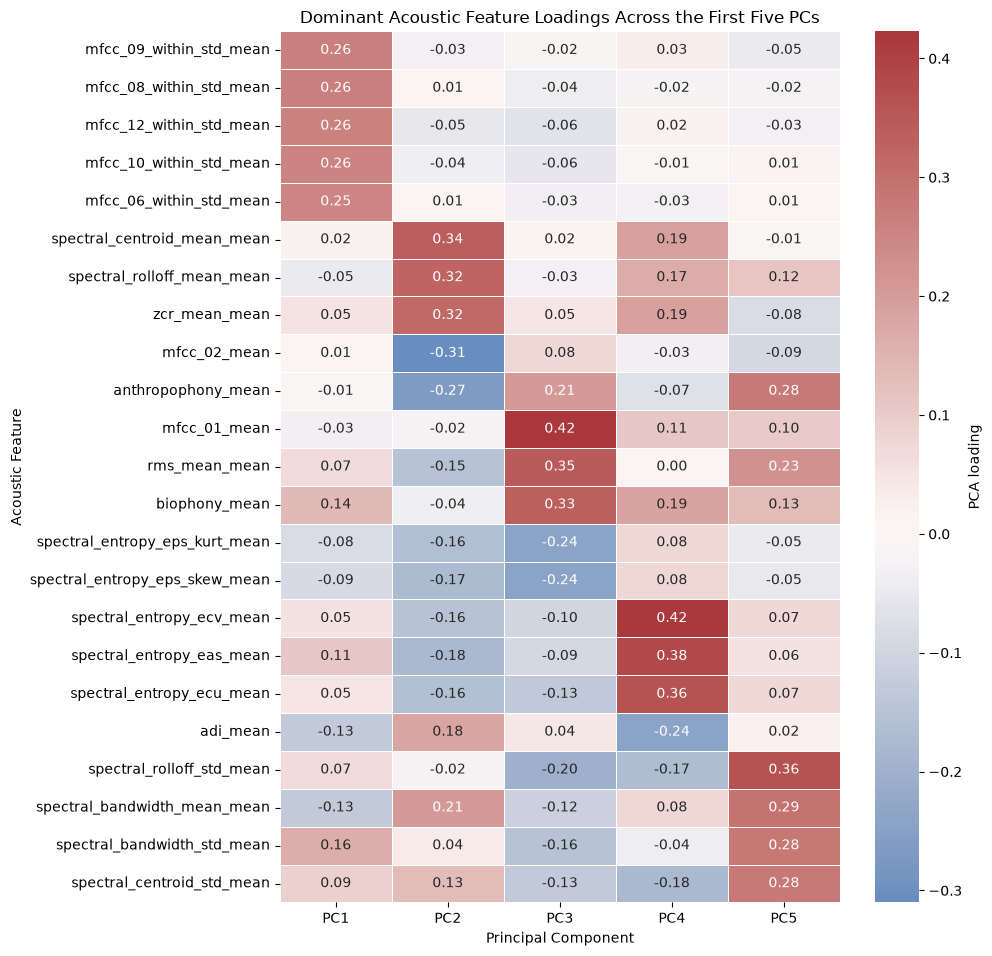

TOP FIVE FEATURES BY PRINCIPAL COMPONENT

PC1


,PC1
mfcc_09_within_std_mean,0.2641
mfcc_08_within_std_mean,0.2637
mfcc_12_within_std_mean,0.2576
mfcc_10_within_std_mean,0.2557
mfcc_06_within_std_mean,0.2533



PC2


,PC2
spectral_centroid_mean_mean,0.3399
spectral_rolloff_mean_mean,0.3239
zcr_mean_mean,0.3167
mfcc_02_mean,-0.3102
anthropophony_mean,-0.2654



PC3


,PC3
mfcc_01_mean,0.4228
rms_mean_mean,0.3454
biophony_mean,0.3314
spectral_entropy_eps_kurt_mean,-0.2419
spectral_entropy_eps_skew_mean,-0.2395



PC4


,PC4
spectral_entropy_ecv_mean,0.4164
spectral_entropy_eas_mean,0.3844
spectral_entropy_ecu_mean,0.3635
adi_mean,-0.2441
zcr_mean_mean,0.1928



PC5


,PC5
spectral_rolloff_std_mean,0.3639
spectral_bandwidth_mean_mean,0.2923
spectral_bandwidth_std_mean,0.2809
spectral_centroid_std_mean,0.2793
anthropophony_mean,0.2774


In [17]:
# ============================================================
# 06B.8 — PCA LOADING HEATMAP: TOP FEATURES BY COMPONENT
# ============================================================

# ------------------------------------------------------------
# 1. Identify top 5 absolute-loading features for each PC
# ------------------------------------------------------------

top_features_by_pc = {}

for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:

    top_features_by_pc[pc] = (
        loading_matrix[pc]
        .abs()
        .sort_values(ascending=False)
        .head(5)
        .index
        .tolist()
    )

# Union of all selected features
selected_features = []

for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    for feature in top_features_by_pc[pc]:
        if feature not in selected_features:
            selected_features.append(feature)

loading_plot_final = loading_matrix.loc[
    selected_features,
    ["PC1", "PC2", "PC3", "PC4", "PC5"]
]

# ------------------------------------------------------------
# 2. Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(10, max(8, len(selected_features) * 0.42))
)

sns.heatmap(
    loading_plot_final,
    center=0,
    cmap="vlag",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={
        "label": "PCA loading"
    }
)

plt.title(
    "Dominant Acoustic Feature Loadings Across the First Five PCs"
)

plt.xlabel("Principal Component")
plt.ylabel("Acoustic Feature")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 3. Report top five features for each PC
# ------------------------------------------------------------

print("=" * 70)
print("TOP FIVE FEATURES BY PRINCIPAL COMPONENT")
print("=" * 70)

for pc, features in top_features_by_pc.items():

    print(f"\n{pc}")

    display(
        loading_matrix.loc[
            features,
            [pc]
        ]
        .sort_values(
            pc,
            key=lambda x: x.abs(),
            ascending=False
        )
        .round(4)
    )

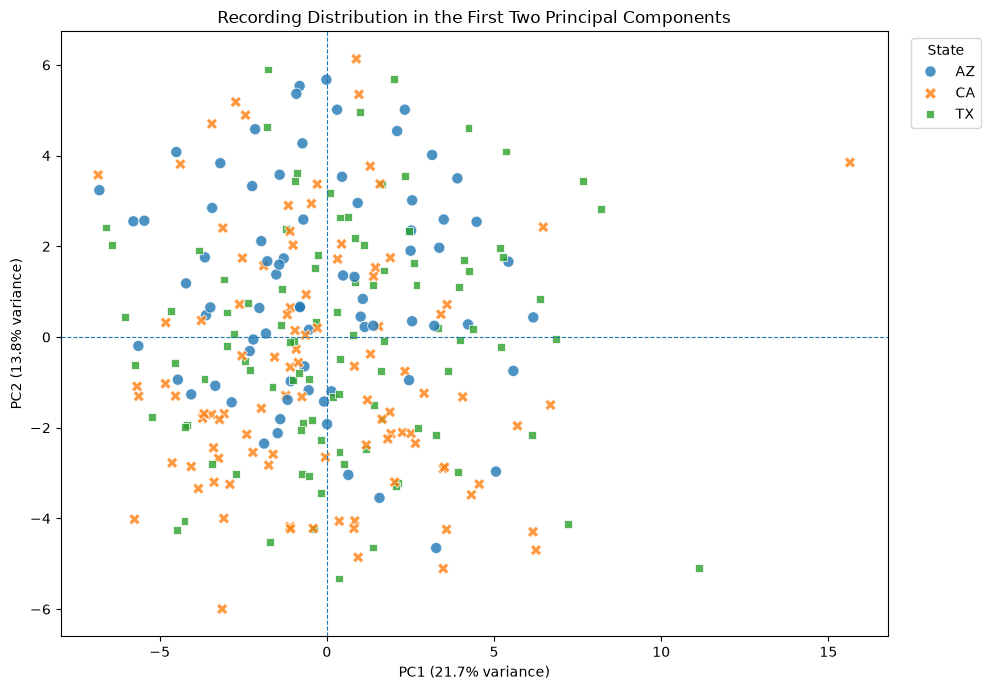

In [18]:
# ============================================================
# 06B.9 — PC1 × PC2 RECORDING SCORE PLOT
# ============================================================

# ------------------------------------------------------------
# 1. Create score dataframe
# ------------------------------------------------------------

pca_scores = pd.DataFrame(
    Z_primary[:, :5],
    columns=[
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
    ]
)

pca_scores["recording_id"] = (
    recording_features["recording_id"].values
)

pca_scores["state"] = (
    recording_features["state"].values
)

pca_scores["species_id"] = (
    recording_features["species_id"].values
)

# ------------------------------------------------------------
# 2. Plot PC1 vs PC2
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue="state",
    style="state",
    s=65,
    alpha=0.80
)

plt.axhline(
    0,
    linewidth=0.8,
    linestyle="--"
)

plt.axvline(
    0,
    linewidth=0.8,
    linestyle="--"
)

plt.title(
    "Recording Distribution in the First Two Principal Components"
)

plt.xlabel(
    f"PC1 ({pca_variance.loc[0, 'explained_variance_ratio']:.1%} variance)"
)

plt.ylabel(
    f"PC2 ({pca_variance.loc[1, 'explained_variance_ratio']:.1%} variance)"
)

plt.legend(
    title="State",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

In [19]:
# ============================================================
# 06B.10 — BOOTSTRAP PCA STABILITY
# ============================================================

# ------------------------------------------------------------
# Purpose
# ------------------------------------------------------------
#
# Assess whether the dominant PCA loading structure is stable
# under resampling of the 275 recordings.
#
# Each bootstrap:
#   1. resamples recordings with replacement
#   2. standardizes the resampled data
#   3. refits PCA
#   4. compares PC1–PC5 loadings with the full-data PCA
#
# PCA signs are arbitrary, so absolute loading correlations
# are used for the stability comparison.
# ------------------------------------------------------------

N_BOOTSTRAPS = 500

rng = np.random.default_rng(RANDOM_SEED)

reference_loadings = (
    pca_primary.components_[:5]
)

bootstrap_correlations = []
bootstrap_variance = []

n_recordings = X_pca_primary.shape[0]

for b in range(N_BOOTSTRAPS):

    # --------------------------------------------------------
    # Resample recordings
    # --------------------------------------------------------

    sample_indices = rng.integers(
        0,
        n_recordings,
        size=n_recordings
    )

    X_boot = X_pca_primary.iloc[
        sample_indices
    ]

    # --------------------------------------------------------
    # Standardize within bootstrap sample
    # --------------------------------------------------------

    scaler_boot = StandardScaler()

    X_boot_scaled = scaler_boot.fit_transform(
        X_boot
    )

    # --------------------------------------------------------
    # Fit PCA
    # --------------------------------------------------------

    pca_boot = PCA(
        random_state=RANDOM_SEED
    )

    pca_boot.fit(X_boot_scaled)

    # --------------------------------------------------------
    # Compare first five loading vectors
    # --------------------------------------------------------

    correlations = []

    for pc in range(5):

        reference = (
            reference_loadings[pc]
        )

        bootstrap = (
            pca_boot.components_[pc]
        )

        correlation = np.corrcoef(
            np.abs(reference),
            np.abs(bootstrap)
        )[0, 1]

        correlations.append(
            correlation
        )

    bootstrap_correlations.append(
        correlations
    )

    bootstrap_variance.append(
        pca_boot.explained_variance_ratio_[:5]
    )


# ------------------------------------------------------------
# Convert results to DataFrames
# ------------------------------------------------------------

bootstrap_correlations = pd.DataFrame(
    bootstrap_correlations,
    columns=[
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
    ]
)

bootstrap_variance = pd.DataFrame(
    bootstrap_variance,
    columns=[
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
    ]
)

# ------------------------------------------------------------
# Summarize loading stability
# ------------------------------------------------------------

stability_summary = pd.DataFrame({
    "PC": [
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
    ],

    "median_loading_correlation":
        bootstrap_correlations.median().values,

    "lower_95":
        bootstrap_correlations.quantile(
            0.025
        ).values,

    "upper_95":
        bootstrap_correlations.quantile(
            0.975
        ).values,
})

print("=" * 70)
print("BOOTSTRAP PCA LOADING STABILITY")
print("=" * 70)

display(
    stability_summary.round(4)
)

# ------------------------------------------------------------
# Summarize explained variance stability
# ------------------------------------------------------------

variance_stability = pd.DataFrame({
    "PC": [
        "PC1",
        "PC2",
        "PC3",
        "PC4",
        "PC5",
    ],

    "median_explained_variance":
        bootstrap_variance.median().values,

    "lower_95":
        bootstrap_variance.quantile(
            0.025
        ).values,

    "upper_95":
        bootstrap_variance.quantile(
            0.975
        ).values,
})

print("\n" + "=" * 70)
print("BOOTSTRAP PCA EXPLAINED VARIANCE STABILITY")
print("=" * 70)

display(
    variance_stability.round(4)
)

# ------------------------------------------------------------
# Compact overall assessment
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PCA STABILITY CHECK")
print("=" * 70)

for pc in range(5):

    median = (
        bootstrap_correlations
        .iloc[:, pc]
        .median()
    )

    lower = (
        bootstrap_correlations
        .iloc[:, pc]
        .quantile(0.025)
    )

    upper = (
        bootstrap_correlations
        .iloc[:, pc]
        .quantile(0.975)
    )

    print(
        f"PC{pc + 1}: "
        f"median = {median:.3f}, "
        f"95% interval = [{lower:.3f}, {upper:.3f}]"
    )

BOOTSTRAP PCA LOADING STABILITY


,PC,median_loading_correlation,lower_95,upper_95
0,PC1,0.9612,0.8690,0.9873
1,PC2,0.9620,0.8915,0.9847
2,PC3,0.8389,0.2820,0.9438
3,PC4,0.6849,-0.1006,0.9322
4,PC5,0.4538,-0.1297,0.8896



BOOTSTRAP PCA EXPLAINED VARIANCE STABILITY


,PC,median_explained_variance,lower_95,upper_95
0,PC1,0.2212,0.2016,0.2454
1,PC2,0.1400,0.1284,0.1528
2,PC3,0.0800,0.0715,0.0895
3,PC4,0.0671,0.0605,0.0742
4,PC5,0.0582,0.0517,0.0646



PCA STABILITY CHECK
PC1: median = 0.961, 95% interval = [0.869, 0.987]
PC2: median = 0.962, 95% interval = [0.892, 0.985]
PC3: median = 0.839, 95% interval = [0.282, 0.944]
PC4: median = 0.685, 95% interval = [-0.101, 0.932]
PC5: median = 0.454, 95% interval = [-0.130, 0.890]


In [20]:
# ============================================================
# 06B.11 — PCA SUBSPACE STABILITY
# ============================================================

# Individual PCs can rotate when eigenvalues are close.
# This checks whether groups of PCs remain stable collectively.

from scipy.linalg import subspace_angles

# ------------------------------------------------------------
# Reference subspaces
# ------------------------------------------------------------

reference_pc12 = pca_primary.components_[:2].T
reference_pc35 = pca_primary.components_[2:5].T
reference_pc15 = pca_primary.components_[:5].T

subspace_results = []

# ------------------------------------------------------------
# Bootstrap subspace stability
# ------------------------------------------------------------

for b in range(N_BOOTSTRAPS):

    sample_indices = rng.integers(
        0,
        n_recordings,
        size=n_recordings
    )

    X_boot = X_pca_primary.iloc[
        sample_indices
    ]

    scaler_boot = StandardScaler()

    X_boot_scaled = scaler_boot.fit_transform(
        X_boot
    )

    pca_boot = PCA(
        random_state=RANDOM_SEED
    )

    pca_boot.fit(X_boot_scaled)

    boot_pc12 = pca_boot.components_[:2].T
    boot_pc35 = pca_boot.components_[2:5].T
    boot_pc15 = pca_boot.components_[:5].T

    # Principal angles are returned in radians.
    # The largest angle is the conservative measure of
    # subspace disagreement.

    angle_pc12 = np.degrees(
        subspace_angles(
            reference_pc12,
            boot_pc12
        )
    )

    angle_pc35 = np.degrees(
        subspace_angles(
            reference_pc35,
            boot_pc35
        )
    )

    angle_pc15 = np.degrees(
        subspace_angles(
            reference_pc15,
            boot_pc15
        )
    )

    subspace_results.append({
        "PC1_PC2_max_angle":
            angle_pc12.max(),

        "PC3_PC5_max_angle":
            angle_pc35.max(),

        "PC1_PC5_max_angle":
            angle_pc15.max(),
    })

subspace_results = pd.DataFrame(
    subspace_results
)

# ------------------------------------------------------------
# Summarize
# ------------------------------------------------------------

subspace_summary = pd.DataFrame({
    "subspace": [
        "PC1–PC2",
        "PC3–PC5",
        "PC1–PC5",
    ],

    "median_max_angle_deg": [
        subspace_results[
            "PC1_PC2_max_angle"
        ].median(),

        subspace_results[
            "PC3_PC5_max_angle"
        ].median(),

        subspace_results[
            "PC1_PC5_max_angle"
        ].median(),
    ],

    "lower_95_deg": [
        subspace_results[
            "PC1_PC2_max_angle"
        ].quantile(0.025),

        subspace_results[
            "PC3_PC5_max_angle"
        ].quantile(0.025),

        subspace_results[
            "PC1_PC5_max_angle"
        ].quantile(0.025),
    ],

    "upper_95_deg": [
        subspace_results[
            "PC1_PC2_max_angle"
        ].quantile(0.975),

        subspace_results[
            "PC3_PC5_max_angle"
        ].quantile(0.975),

        subspace_results[
            "PC1_PC5_max_angle"
        ].quantile(0.975),
    ],
})

print("=" * 70)
print("PCA SUBSPACE STABILITY")
print("=" * 70)

display(
    subspace_summary.round(2)
)

PCA SUBSPACE STABILITY


,subspace,median_max_angle_deg,lower_95_deg,upper_95_deg
0,PC1–PC2,10.65,7.28,16.93
1,PC3–PC5,34.49,19.09,82.97
2,PC1–PC5,34.49,18.65,83.09


In [26]:


# ============================================================
# 06B.3 — YEO–JOHNSON PCA REPRESENTATION
# ============================================================

from sklearn.preprocessing import PowerTransformer, StandardScaler

print("=" * 70)
print("YEO–JOHNSON PCA REPRESENTATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. INPUT
# ------------------------------------------------------------
# Same 275 recordings × 50 primary acoustic features used
# for the baseline and distribution-adjusted representations.

X_yeojohnson = X_primary.copy()

print("Input shape:", X_yeojohnson.shape)
print(
    "Missing values:",
    X_yeojohnson.isna().sum().sum()
)
print(
    "Non-finite values:",
    (~np.isfinite(
        X_yeojohnson.to_numpy()
    )).sum()
)

# ------------------------------------------------------------
# 2. YEO–JOHNSON TRANSFORMATION
# ------------------------------------------------------------
#
# Yeo–Johnson is applied feature-by-feature.
#
# Unlike log/log1p transformations, Yeo–Johnson can handle:
#   - positive values
#   - zero
#   - negative values
#
# standardize=False keeps transformation and standardization
# as explicitly separate analytical steps.
# ------------------------------------------------------------

yeojohnson_transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

X_yeojohnson_transformed = (
    yeojohnson_transformer.fit_transform(
        X_yeojohnson
    )
)

X_yeojohnson_transformed = pd.DataFrame(
    X_yeojohnson_transformed,
    index=X_yeojohnson.index,
    columns=X_yeojohnson.columns
)

# ------------------------------------------------------------
# 3. STANDARDIZATION
# ------------------------------------------------------------

scaler_yeojohnson = StandardScaler()

X_yeojohnson_scaled = (
    scaler_yeojohnson.fit_transform(
        X_yeojohnson_transformed
    )
)

# ------------------------------------------------------------
# 4. BASIC VALIDATION
# ------------------------------------------------------------

assert (
    X_yeojohnson_scaled.shape
    == X_yeojohnson.shape
)

assert np.isfinite(
    X_yeojohnson_scaled
).all()

# ------------------------------------------------------------
# 5. STANDARDIZATION DIAGNOSTICS
# ------------------------------------------------------------

column_means = (
    X_yeojohnson_scaled.mean(axis=0)
)

column_stds = (
    X_yeojohnson_scaled.std(axis=0)
)

max_abs_mean = np.max(
    np.abs(column_means)
)

max_abs_std_error = np.max(
    np.abs(column_stds - 1)
)

print("\n" + "=" * 70)
print("STANDARDIZATION VALIDATION")
print("=" * 70)

print(
    "Maximum absolute standardized mean:",
    max_abs_mean
)

print(
    "Maximum absolute standardized std error:",
    max_abs_std_error
)

# A small floating-point tolerance is used here.
# The observed ACI deviation (~5e-7) is numerical and has
# no meaningful effect on PCA.

assert max_abs_mean < 1e-6
assert max_abs_std_error < 1e-6

# ------------------------------------------------------------
# 6. SKEWNESS COMPARISON
# ------------------------------------------------------------

yeojohnson_skew = pd.DataFrame({
    "feature": X_yeojohnson.columns,
    "baseline_skew": (
        X_yeojohnson.skew().values
    ),
    "yeojohnson_skew": (
        X_yeojohnson_transformed.skew().values
    )
})

yeojohnson_skew[
    "absolute_skew_reduction"
] = (
    yeojohnson_skew["baseline_skew"].abs()
    - yeojohnson_skew["yeojohnson_skew"].abs()
)

yeojohnson_skew[
    "absolute_yeojohnson_skew"
] = (
    yeojohnson_skew["yeojohnson_skew"].abs()
)

print("\n" + "=" * 70)
print("YEO–JOHNSON SKEWNESS EFFECT")
print("=" * 70)

baseline_mean_abs_skew = (
    X_yeojohnson.skew().abs().mean()
)

yeojohnson_mean_abs_skew = (
    X_yeojohnson_transformed.skew().abs().mean()
)

print(
    "Mean absolute skew — baseline:",
    round(
        baseline_mean_abs_skew,
        4
    )
)

print(
    "Mean absolute skew — Yeo–Johnson:",
    round(
        yeojohnson_mean_abs_skew,
        4
    )
)

print(
    "Mean absolute skew reduction:",
    round(
        baseline_mean_abs_skew
        - yeojohnson_mean_abs_skew,
        4
    )
)

print("\nLargest skewness reductions:")

display(
    yeojohnson_skew[
        [
            "feature",
            "baseline_skew",
            "yeojohnson_skew",
            "absolute_skew_reduction"
        ]
    ]
    .sort_values(
        "absolute_skew_reduction",
        ascending=False
    )
    .head(15)
    .round(4)
)

print("\nLargest remaining absolute skew:")

display(
    yeojohnson_skew[
        [
            "feature",
            "yeojohnson_skew",
            "absolute_yeojohnson_skew"
        ]
    ]
    .sort_values(
        "absolute_yeojohnson_skew",
        ascending=False
    )
    .head(15)
    .round(4)
)

# ------------------------------------------------------------
# 7. YEO–JOHNSON TRANSFORMATION PARAMETERS
# ------------------------------------------------------------

yeojohnson_parameters = pd.DataFrame({
    "feature": X_yeojohnson.columns,
    "lambda": (
        yeojohnson_transformer.lambdas_
    )
})

print("\n" + "=" * 70)
print("YEO–JOHNSON TRANSFORMATION PARAMETERS")
print("=" * 70)

display(
    yeojohnson_parameters
    .sort_values("lambda")
    .round(4)
)

# ------------------------------------------------------------
# 8. FINAL REPRESENTATION VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

print(
    "Same observations:",
    X_yeojohnson.index.equals(
        X_primary.index
    )
)

print(
    "Same features:",
    X_yeojohnson.columns.tolist()
    == X_primary.columns.tolist()
)

print(
    "Same shape:",
    X_yeojohnson_scaled.shape
    == X_primary.shape
)

print(
    "No non-finite values:",
    np.isfinite(
        X_yeojohnson_scaled
    ).all()
)

print(
    "All standardized means within 1e-6:",
    np.all(
        np.abs(
            X_yeojohnson_scaled.mean(axis=0)
        ) < 1e-6
    )
)

print(
    "All standardized stds within 1e-6:",
    np.all(
        np.abs(
            X_yeojohnson_scaled.std(axis=0) - 1
        ) < 1e-6
    )
)

print("\nYeo–Johnson representation ready for PCA comparison.")


YEO–JOHNSON PCA REPRESENTATION
Input shape: (275, 50)
Missing values: 0
Non-finite values: 0

STANDARDIZATION VALIDATION
Maximum absolute standardized mean: 5.105285092810163e-07
Maximum absolute standardized std error: 2.220446049250313e-16

YEO–JOHNSON SKEWNESS EFFECT
Mean absolute skew — baseline: 1.5823
Mean absolute skew — Yeo–Johnson: 0.0775
Mean absolute skew reduction: 1.5048

Largest skewness reductions:


,feature,baseline_skew,yeojohnson_skew,absolute_skew_reduction
4,ndsi_ratio_ba_mean,16.0770,0.3845,15.6925
6,biophony_mean,6.0546,-0.0658,5.9888
11,spectral_entropy_eps_kurt_mean,5.1252,0.0032,5.1220
5,anthropophony_mean,4.8516,-0.0099,4.8417
2,bioacoustic_index_mean,4.4555,-0.0133,4.4422
14,rms_mean_mean,3.5972,0.4555,3.1417
12,spectral_entropy_eps_skew_mean,2.8201,-0.0004,2.8197
48,mfcc_13_mean,2.5818,-0.2614,2.3204
47,mfcc_12_within_std_mean,1.5785,0.0011,1.5773
49,mfcc_13_within_std_mean,1.4931,0.0327,1.4604



Largest remaining absolute skew:


,feature,yeojohnson_skew,absolute_yeojohnson_skew
14,rms_mean_mean,0.4555,0.4555
4,ndsi_ratio_ba_mean,0.3845,0.3845
1,adi_mean,-0.3178,0.3178
42,mfcc_10_mean,0.2794,0.2794
46,mfcc_12_mean,0.2734,0.2734
48,mfcc_13_mean,-0.2614,0.2614
30,mfcc_04_mean,0.2591,0.2591
15,rms_std_mean,0.2552,0.2552
26,mfcc_02_mean,0.2011,0.2011
38,mfcc_08_mean,0.1036,0.1036



YEO–JOHNSON TRANSFORMATION PARAMETERS


,feature,lambda
14,rms_mean_mean,-38.6617
15,rms_std_mean,-35.7301
17,zcr_std_mean,-14.7385
10,spectral_entropy_eps_mean,-3.7138
0,aci_mean,-3.4217
16,zcr_mean_mean,-3.0208
9,spectral_entropy_ecv_mean,-0.9226
49,mfcc_13_within_std_mean,-0.6757
7,spectral_entropy_eas_mean,-0.6355
12,spectral_entropy_eps_skew_mean,-0.6348



FINAL VALIDATION
Same observations: True
Same features: True
Same shape: True
No non-finite values: True
All standardized means within 1e-6: True
All standardized stds within 1e-6: True

Yeo–Johnson representation ready for PCA comparison.


In [27]:
# ============================================================
# 06B.4 — BLOCK-BALANCED PCA REPRESENTATION
# ============================================================

from sklearn.preprocessing import StandardScaler

print("=" * 70)
print("BLOCK-BALANCED PCA REPRESENTATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. DEFINE FEATURE BLOCKS
# ------------------------------------------------------------

FEATURE_BLOCKS = {
    "acoustic_indices": [
        "aci_mean",
        "adi_mean",
        "bioacoustic_index_mean",
        "ndsi_mean",
        "ndsi_ratio_ba_mean",
        "anthropophony_mean",
        "biophony_mean",
    ],

    "entropy": [
        "spectral_entropy_eas_mean",
        "spectral_entropy_ecu_mean",
        "spectral_entropy_ecv_mean",
        "spectral_entropy_eps_mean",
        "spectral_entropy_eps_kurt_mean",
        "spectral_entropy_eps_skew_mean",
        "temporal_entropy_mean",
    ],

    "energy_amplitude": [
        "rms_mean_mean",
        "rms_std_mean",
        "zcr_mean_mean",
        "zcr_std_mean",
    ],

    "spectral_shape": [
        "spectral_centroid_mean_mean",
        "spectral_centroid_std_mean",
        "spectral_bandwidth_mean_mean",
        "spectral_bandwidth_std_mean",
        "spectral_rolloff_mean_mean",
        "spectral_rolloff_std_mean",
    ],

    "mfcc_means": [
        "mfcc_01_mean",
        "mfcc_02_mean",
        "mfcc_03_mean",
        "mfcc_04_mean",
        "mfcc_05_mean",
        "mfcc_06_mean",
        "mfcc_07_mean",
        "mfcc_08_mean",
        "mfcc_09_mean",
        "mfcc_10_mean",
        "mfcc_11_mean",
        "mfcc_12_mean",
        "mfcc_13_mean",
    ],

    "mfcc_within_window_variability": [
        "mfcc_01_within_std_mean",
        "mfcc_02_within_std_mean",
        "mfcc_03_within_std_mean",
        "mfcc_04_within_std_mean",
        "mfcc_05_within_std_mean",
        "mfcc_06_within_std_mean",
        "mfcc_07_within_std_mean",
        "mfcc_08_within_std_mean",
        "mfcc_09_within_std_mean",
        "mfcc_10_within_std_mean",
        "mfcc_11_within_std_mean",
        "mfcc_12_within_std_mean",
        "mfcc_13_within_std_mean",
    ],
}

# ------------------------------------------------------------
# 2. AUDIT FEATURE ASSIGNMENT
# ------------------------------------------------------------

all_block_features = [
    feature
    for block in FEATURE_BLOCKS.values()
    for feature in block
]

primary_feature_set = set(PRIMARY_FEATURES)
block_feature_set = set(all_block_features)

duplicate_features = [
    feature
    for feature in all_block_features
    if all_block_features.count(feature) > 1
]

missing_from_blocks = sorted(
    primary_feature_set - block_feature_set
)

unexpected_features = sorted(
    block_feature_set - primary_feature_set
)

print("\nFeature-block audit:")
print(
    "  Primary features:",
    len(PRIMARY_FEATURES)
)

print(
    "  Features assigned to blocks:",
    len(all_block_features)
)

print(
    "  Unique assigned features:",
    len(block_feature_set)
)

print(
    "  Duplicate assignments:",
    len(set(duplicate_features))
)

print(
    "  Missing primary features:",
    len(missing_from_blocks)
)

print(
    "  Unexpected features:",
    len(unexpected_features)
)

if duplicate_features:
    print("\nDuplicate features:")
    print(sorted(set(duplicate_features)))

if missing_from_blocks:
    print("\nMissing features:")
    print(missing_from_blocks)

if unexpected_features:
    print("\nUnexpected features:")
    print(unexpected_features)

# Do not proceed unless the mapping is exact.
assert len(all_block_features) == len(
    set(all_block_features)
)

assert block_feature_set == primary_feature_set

# ------------------------------------------------------------
# 3. BLOCK SIZE SUMMARY
# ------------------------------------------------------------

block_summary = pd.DataFrame({
    "block": list(FEATURE_BLOCKS.keys()),
    "n_features": [
        len(features)
        for features in FEATURE_BLOCKS.values()
    ],
})

print("\n" + "=" * 70)
print("FEATURE BLOCKS")
print("=" * 70)

display(block_summary)

# ------------------------------------------------------------
# 4. STANDARDIZE EACH FEATURE
# ------------------------------------------------------------

X_block_standardized = pd.DataFrame(
    StandardScaler().fit_transform(
        X_primary
    ),
    index=X_primary.index,
    columns=X_primary.columns,
)

# ------------------------------------------------------------
# 5. BALANCE BLOCK CONTRIBUTIONS
# ------------------------------------------------------------
#
# After feature-level standardization, each feature has
# approximately unit variance.
#
# A block with p features therefore contributes approximately
# p units of total variance.
#
# Dividing each block by sqrt(p) gives each block approximately
# equal total variance:
#
#       p × (1 / sqrt(p))² ≈ 1
#
# This prevents a feature-rich block, such as MFCCs, from
# dominating simply because it contains more variables.
# ------------------------------------------------------------

X_block_balanced = X_block_standardized.copy()

for block_name, features in FEATURE_BLOCKS.items():

    block_size = len(features)

    X_block_balanced[
        features
    ] = (
        X_block_balanced[features]
        / np.sqrt(block_size)
    )

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert X_block_balanced.shape == X_primary.shape

assert X_block_balanced.columns.tolist() == (
    X_primary.columns.tolist()
)

assert np.isfinite(
    X_block_balanced.to_numpy()
).all()

# Check feature-level standardization BEFORE balancing.
standardized_means = (
    X_block_standardized.mean(axis=0)
)

standardized_stds = (
    X_block_standardized.std(axis=0)
)

print("\n" + "=" * 70)
print("FEATURE-LEVEL STANDARDIZATION")
print("=" * 70)

print(
    "Maximum absolute mean:",
    np.max(
        np.abs(standardized_means)
    )
)

print(
    "Maximum absolute std error:",
    np.max(
        np.abs(standardized_stds - 1)
    )
)

# ------------------------------------------------------------
# 7. VERIFY BLOCK BALANCE
# ------------------------------------------------------------

block_variance_summary = []

for block_name, features in FEATURE_BLOCKS.items():

    block_data = X_block_balanced[
        features
    ]

    # Sum of feature variances within each block.
    total_variance = np.var(
        block_data.to_numpy(),
        axis=0,
        ddof=0
    ).sum()

    block_variance_summary.append({
        "block": block_name,
        "n_features": len(features),
        "total_variance": total_variance,
    })

block_variance_summary = pd.DataFrame(
    block_variance_summary
)

print("\n" + "=" * 70)
print("BLOCK VARIANCE BALANCE")
print("=" * 70)

display(
    block_variance_summary.round(4)
)

# ------------------------------------------------------------
# 8. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

print(
    "Same observations:",
    X_block_balanced.index.equals(
        X_primary.index
    )
)

print(
    "Same features:",
    X_block_balanced.columns.tolist()
    == X_primary.columns.tolist()
)

print(
    "Same shape:",
    X_block_balanced.shape
    == X_primary.shape
)

print(
    "No non-finite values:",
    np.isfinite(
        X_block_balanced.to_numpy()
    ).all()
)

print(
    "\nBlock-balanced representation ready for PCA comparison."
)

BLOCK-BALANCED PCA REPRESENTATION

Feature-block audit:
  Primary features: 50
  Features assigned to blocks: 50
  Unique assigned features: 50
  Duplicate assignments: 0
  Missing primary features: 0
  Unexpected features: 0

FEATURE BLOCKS


,block,n_features
0,acoustic_indices,7
1,entropy,7
2,energy_amplitude,4
3,spectral_shape,6
4,mfcc_means,13
5,mfcc_within_window_variability,13



FEATURE-LEVEL STANDARDIZATION
Maximum absolute mean: 6.653263798480939e-16
Maximum absolute std error: 0.0018231555701317959

BLOCK VARIANCE BALANCE


,block,n_features,total_variance
0,acoustic_indices,7,1.0
1,entropy,7,1.0
2,energy_amplitude,4,1.0
3,spectral_shape,6,1.0
4,mfcc_means,13,1.0
5,mfcc_within_window_variability,13,1.0



FINAL VALIDATION
Same observations: True
Same features: True
Same shape: True
No non-finite values: True

Block-balanced representation ready for PCA comparison.


In [28]:
# ============================================================
# 06B.5 — NDSI-FAMILY SENSITIVITY REPRESENTATIONS
# ============================================================

from sklearn.preprocessing import StandardScaler

print("=" * 70)
print("NDSI-FAMILY PCA SENSITIVITY")
print("=" * 70)

# ------------------------------------------------------------
# 1. DEFINE THE NDSI-RELATED FEATURE FAMILY
# ------------------------------------------------------------

NDSI_DERIVED_FEATURES = [
    "ndsi_mean",
    "ndsi_ratio_ba_mean",
]

NDSI_FULL_FAMILY = [
    "ndsi_mean",
    "ndsi_ratio_ba_mean",
    "anthropophony_mean",
    "biophony_mean",
]

# ------------------------------------------------------------
# 2. AUDIT FEATURE AVAILABILITY
# ------------------------------------------------------------

missing_ndsi_features = [
    feature
    for feature in NDSI_FULL_FAMILY
    if feature not in PRIMARY_FEATURES
]

assert len(missing_ndsi_features) == 0

print("\nNDSI-derived features:")
for feature in NDSI_DERIVED_FEATURES:
    print(" -", feature)

print("\nFull NDSI-related family:")
for feature in NDSI_FULL_FAMILY:
    print(" -", feature)

# ------------------------------------------------------------
# 3. VARIANT A
# ------------------------------------------------------------
# Remove only mathematically derived NDSI variables.
#
# Underlying biophony and low-frequency energy variables
# remain available.
# ------------------------------------------------------------

NDSI_DERIVED_SENSITIVITY_FEATURES = [
    feature
    for feature in PRIMARY_FEATURES
    if feature not in NDSI_DERIVED_FEATURES
]

X_ndsi_derived_sensitivity = (
    X_primary[
        NDSI_DERIVED_SENSITIVITY_FEATURES
    ].copy()
)

scaler_ndsi_derived = StandardScaler()

X_ndsi_derived_sensitivity_scaled = (
    scaler_ndsi_derived.fit_transform(
        X_ndsi_derived_sensitivity
    )
)

# ------------------------------------------------------------
# 4. VARIANT B
# ------------------------------------------------------------
# Remove the entire NDSI-related family.
#
# This is deliberately more conservative:
# it asks whether the broader PCA structure persists
# without any of these four variables.
# ------------------------------------------------------------

NDSI_FULL_SENSITIVITY_FEATURES = [
    feature
    for feature in PRIMARY_FEATURES
    if feature not in NDSI_FULL_FAMILY
]

X_ndsi_full_sensitivity = (
    X_primary[
        NDSI_FULL_SENSITIVITY_FEATURES
    ].copy()
)

scaler_ndsi_full = StandardScaler()

X_ndsi_full_sensitivity_scaled = (
    scaler_ndsi_full.fit_transform(
        X_ndsi_full_sensitivity
    )
)

# ------------------------------------------------------------
# 5. VALIDATION
# ------------------------------------------------------------

assert np.isfinite(
    X_ndsi_derived_sensitivity_scaled
).all()

assert np.isfinite(
    X_ndsi_full_sensitivity_scaled
).all()

assert (
    X_ndsi_derived_sensitivity_scaled.shape[0]
    == X_primary.shape[0]
)

assert (
    X_ndsi_full_sensitivity_scaled.shape[0]
    == X_primary.shape[0]
)

# ------------------------------------------------------------
# 6. STANDARDIZATION CHECK
# ------------------------------------------------------------

derived_means = (
    X_ndsi_derived_sensitivity_scaled.mean(axis=0)
)

derived_stds = (
    X_ndsi_derived_sensitivity_scaled.std(axis=0)
)

full_means = (
    X_ndsi_full_sensitivity_scaled.mean(axis=0)
)

full_stds = (
    X_ndsi_full_sensitivity_scaled.std(axis=0)
)

print("\n" + "=" * 70)
print("REPRESENTATION SIZES")
print("=" * 70)

print(
    "Primary representation:",
    X_primary.shape
)

print(
    "NDSI-derived excluded:",
    X_ndsi_derived_sensitivity_scaled.shape
)

print(
    "Full NDSI-family excluded:",
    X_ndsi_full_sensitivity_scaled.shape
)

print("\n" + "=" * 70)
print("STANDARDIZATION VALIDATION")
print("=" * 70)

print(
    "NDSI-derived excluded — max |mean|:",
    np.max(np.abs(derived_means))
)

print(
    "NDSI-derived excluded — max |std-1|:",
    np.max(np.abs(derived_stds - 1))
)

print(
    "Full NDSI-family excluded — max |mean|:",
    np.max(np.abs(full_means))
)

print(
    "Full NDSI-family excluded — max |std-1|:",
    np.max(np.abs(full_stds - 1))
)

# ------------------------------------------------------------
# 7. FEATURE DIFFERENCES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE REMOVAL AUDIT")
print("=" * 70)

print(
    "Removed in targeted sensitivity:",
    sorted(
        set(PRIMARY_FEATURES)
        - set(NDSI_DERIVED_SENSITIVITY_FEATURES)
    )
)

print(
    "\nRemoved in full-family sensitivity:",
    sorted(
        set(PRIMARY_FEATURES)
        - set(NDSI_FULL_SENSITIVITY_FEATURES)
    )
)

# ------------------------------------------------------------
# 8. FINAL VALIDATION
# ------------------------------------------------------------

assert (
    len(NDSI_DERIVED_SENSITIVITY_FEATURES)
    == len(PRIMARY_FEATURES) - 2
)

assert (
    len(NDSI_FULL_SENSITIVITY_FEATURES)
    == len(PRIMARY_FEATURES) - 4
)

assert (
    X_ndsi_derived_sensitivity_scaled.shape[1]
    == 48
)

assert (
    X_ndsi_full_sensitivity_scaled.shape[1]
    == 46
)

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

print(
    "Targeted NDSI sensitivity ready:",
    X_ndsi_derived_sensitivity_scaled.shape
)

print(
    "Full NDSI-family sensitivity ready:",
    X_ndsi_full_sensitivity_scaled.shape
)

print(
    "\nNDSI-family sensitivity representations ready "
    "for 06B comparison."
)

NDSI-FAMILY PCA SENSITIVITY

NDSI-derived features:
 - ndsi_mean
 - ndsi_ratio_ba_mean

Full NDSI-related family:
 - ndsi_mean
 - ndsi_ratio_ba_mean
 - anthropophony_mean
 - biophony_mean

REPRESENTATION SIZES
Primary representation: (275, 50)
NDSI-derived excluded: (275, 48)
Full NDSI-family excluded: (275, 46)

STANDARDIZATION VALIDATION
NDSI-derived excluded — max |mean|: 6.653263798480939e-16
NDSI-derived excluded — max |std-1|: 2.220446049250313e-16
Full NDSI-family excluded — max |mean|: 6.653263798480939e-16
Full NDSI-family excluded — max |std-1|: 2.220446049250313e-16

FEATURE REMOVAL AUDIT
Removed in targeted sensitivity: ['ndsi_mean', 'ndsi_ratio_ba_mean']

Removed in full-family sensitivity: ['anthropophony_mean', 'biophony_mean', 'ndsi_mean', 'ndsi_ratio_ba_mean']

FINAL VALIDATION
Targeted NDSI sensitivity ready: (275, 48)
Full NDSI-family sensitivity ready: (275, 46)

NDSI-family sensitivity representations ready for 06B comparison.


In [30]:
# ============================================================
# 6B.6 — PCA REPRESENTATION COMPARISON
# ============================================================

print("=" * 70)
print("6B PCA REPRESENTATION COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# 1. Collect all representations
# ------------------------------------------------------------

PCA_REPRESENTATIONS = {
    "baseline": {
        "X": X_baseline_scaled,
        "n_features": X_baseline_scaled.shape[1],
        "purpose": "Reference representation: standardized original features"
    },
    "distribution_aware": {
        "X": X_transformed_scaled,
        "n_features": X_transformed_scaled.shape[1],
        "purpose": "Reduce influence of selected highly skewed features"
    },
    "yeo_johnson": {
        "X": X_yeojohnson_scaled,
        "n_features": X_yeojohnson_scaled.shape[1],
        "purpose": "Distribution normalization using Yeo-Johnson transformation"
    },
    "block_balanced": {
        "X": X_block_balanced.to_numpy(),
        "n_features": X_block_balanced.shape[1],
        "purpose": "Balance contribution across acoustic feature families"
    },
    "ndsi_derived_excluded": {
        "X": X_ndsi_derived_sensitivity_scaled,
        "n_features": X_ndsi_derived_sensitivity_scaled.shape[1],
        "purpose": "Sensitivity to removal of NDSI-derived variables"
    },
    "ndsi_family_excluded": {
        "X": X_ndsi_full_sensitivity_scaled,
        "n_features": X_ndsi_full_sensitivity_scaled.shape[1],
        "purpose": "Sensitivity to removal of the full NDSI-related family"
    },
}


# ------------------------------------------------------------
# 2. Structural validation
# ------------------------------------------------------------

expected_n = X_primary.shape[0]

comparison_rows = []

for name, info in PCA_REPRESENTATIONS.items():

    X = np.asarray(info["X"])

    comparison_rows.append({
        "representation": name,
        "n_recordings": X.shape[0],
        "n_features": X.shape[1],
        "finite": np.isfinite(X).all(),
        "same_observations": X.shape[0] == expected_n,
        "purpose": info["purpose"]
    })

representation_comparison = pd.DataFrame(comparison_rows)


# ------------------------------------------------------------
# 3. Feature standardization diagnostics
#
# For the ordinary representations, each feature should have
# variance ~1.
#
# BLOCK-BALANCED IS DIFFERENT:
# its feature variances are intentionally reduced according
# to block size so that each feature family contributes
# approximately equal TOTAL variance.
# ------------------------------------------------------------

standardization_rows = []

for name, info in PCA_REPRESENTATIONS.items():

    X = np.asarray(info["X"])

    means = np.mean(X, axis=0)
    variances = np.var(X, axis=0, ddof=0)

    row = {
        "representation": name,
        "max_abs_mean": np.max(np.abs(means)),
    }

    if name == "block_balanced":
        row["variance_validation"] = (
            "Block-level total variance; not individual feature variance"
        )
        row["max_abs_feature_std_error"] = np.nan
    else:
        stds = np.std(X, axis=0, ddof=0)
        row["variance_validation"] = "Individual feature standardization"
        row["max_abs_feature_std_error"] = np.max(
            np.abs(stds - 1)
        )

    standardization_rows.append(row)

standardization_comparison = pd.DataFrame(standardization_rows)


# ------------------------------------------------------------
# 4. Validate block-balanced total variance
# ------------------------------------------------------------

block_variance_rows = []

X_block = np.asarray(X_block_balanced)

for block_name, features in FEATURE_BLOCKS.items():

    block_indices = [
        X_primary.columns.get_loc(feature)
        for feature in features
    ]

    block_X = X_block[:, block_indices]

    total_variance = np.var(block_X, axis=0, ddof=0).sum()

    block_variance_rows.append({
        "block": block_name,
        "n_features": len(features),
        "total_variance": total_variance
    })

block_variance_comparison = pd.DataFrame(block_variance_rows)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REPRESENTATION STRUCTURE")
print("=" * 70)

display(representation_comparison)


print("\n" + "=" * 70)
print("STANDARDIZATION / SCALING DIAGNOSTICS")
print("=" * 70)

display(standardization_comparison)


print("\n" + "=" * 70)
print("BLOCK-BALANCED VARIANCE")
print("=" * 70)

display(block_variance_comparison)


# ------------------------------------------------------------
# 6. Final validation
# ------------------------------------------------------------

assert len(PCA_REPRESENTATIONS) == 6

for name, info in PCA_REPRESENTATIONS.items():

    X = np.asarray(info["X"])

    # Same observations
    assert X.shape[0] == expected_n, (
        f"{name}: incorrect number of observations"
    )

    # No invalid values
    assert np.isfinite(X).all(), (
        f"{name}: non-finite values detected"
    )

    # Centered
    assert np.max(np.abs(np.mean(X, axis=0))) < 1e-5, (
        f"{name}: centering failed"
    )

    # Ordinary representations:
    # individual features should have unit variance.
    if name != "block_balanced":

        assert np.max(
            np.abs(np.std(X, axis=0, ddof=0) - 1)
        ) < 1e-5, (
            f"{name}: standardization failed"
        )


# Block-balanced representation:
# each feature family should contribute approximately equal
# total variance.

assert np.allclose(
    block_variance_comparison["total_variance"].to_numpy(),
    1.0,
    atol=1e-10
), "Block-balanced total variance is not equal across blocks."


print("\n" + "=" * 70)
print("06B VALIDATION PASSED")
print("=" * 70)

print("""
All six PCA representations:

✓ contain the same 275 recordings
✓ contain no non-finite values
✓ are centered
✓ ordinary representations are individually standardized
✓ block-balanced representation has equal total variance across blocks

06B representation construction is complete.
""")

6B PCA REPRESENTATION COMPARISON

REPRESENTATION STRUCTURE


,representation,n_recordings,n_features,finite,same_observations,purpose
0,baseline,275,50,True,True,Reference representation: standardized origina...
1,distribution_aware,275,50,True,True,Reduce influence of selected highly skewed fea...
2,yeo_johnson,275,50,True,True,Distribution normalization using Yeo-Johnson t...
3,block_balanced,275,50,True,True,Balance contribution across acoustic feature f...
4,ndsi_derived_excluded,275,48,True,True,Sensitivity to removal of NDSI-derived variables
5,ndsi_family_excluded,275,46,True,True,Sensitivity to removal of the full NDSI-relate...



STANDARDIZATION / SCALING DIAGNOSTICS


,representation,max_abs_mean,variance_validation,max_abs_feature_std_error
0,baseline,6.653264e-16,Individual feature standardization,2.220446e-16
1,distribution_aware,6.653264e-16,Individual feature standardization,2.220446e-16
2,yeo_johnson,5.105285e-07,Individual feature standardization,2.220446e-16
3,block_balanced,2.583792e-16,Block-level total variance; not individual fea...,NaN
4,ndsi_derived_excluded,6.653264e-16,Individual feature standardization,2.220446e-16
5,ndsi_family_excluded,6.653264e-16,Individual feature standardization,2.220446e-16



BLOCK-BALANCED VARIANCE


,block,n_features,total_variance
0,acoustic_indices,7,1.0
1,entropy,7,1.0
2,energy_amplitude,4,1.0
3,spectral_shape,6,1.0
4,mfcc_means,13,1.0
5,mfcc_within_window_variability,13,1.0



06B VALIDATION PASSED

All six PCA representations:

✓ contain the same 275 recordings
✓ contain no non-finite values
✓ are centered
✓ ordinary representations are individually standardized
✓ block-balanced representation has equal total variance across blocks

06B representation construction is complete.



In [31]:
# ============================================================
# 06B — SAVE VALIDATED PCA REPRESENTATIONS
# ============================================================

from pathlib import Path
import joblib
import json

# Project-level analysis artifact directory
PROJECT_ROOT = Path.cwd().parents[1]
ARTIFACT_DIR = PROJECT_ROOT / "data" / "processed" / "pca_representations"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Save representations
# ------------------------------------------------------------

representation_arrays = {
    "baseline": np.asarray(X_baseline_scaled),
    "distribution_aware": np.asarray(X_transformed_scaled),
    "yeo_johnson": np.asarray(X_yeojohnson_scaled),
    "block_balanced": np.asarray(X_block_balanced),
    "ndsi_derived_excluded": np.asarray(
        X_ndsi_derived_sensitivity_scaled
    ),
    "ndsi_family_excluded": np.asarray(
        X_ndsi_full_sensitivity_scaled
    ),
}

# Save feature names separately because the representations
# have different numbers of columns.
representation_feature_names = {
    "baseline": list(X_primary.columns),
    "distribution_aware": list(X_primary.columns),
    "yeo_johnson": list(X_primary.columns),
    "block_balanced": list(X_primary.columns),
    "ndsi_derived_excluded": [
        c for c in X_primary.columns
        if c not in NDSI_DERIVED_FEATURES
    ],
    "ndsi_family_excluded": [
        c for c in X_primary.columns
        if c not in NDSI_FULL_FAMILY
    ],
}

# ------------------------------------------------------------
# Write files
# ------------------------------------------------------------

for name, X in representation_arrays.items():

    np.save(
        ARTIFACT_DIR / f"{name}.npy",
        X
    )

    with open(
        ARTIFACT_DIR / f"{name}_features.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            representation_feature_names[name],
            f,
            indent=2
        )

# Save recording IDs so observation identity is explicit.
recording_ids = recording_features["recording_id"].astype(str).tolist()

with open(
    ARTIFACT_DIR / "recording_ids.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(recording_ids, f, indent=2)

# Save representation metadata
representation_metadata = {
    "n_recordings": len(recording_ids),
    "representations": {
        name: {
            "n_features": int(X.shape[1]),
            "n_recordings": int(X.shape[0]),
        }
        for name, X in representation_arrays.items()
    }
}

with open(
    ARTIFACT_DIR / "representation_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        representation_metadata,
        f,
        indent=2
    )

print("=" * 70)
print("06B REPRESENTATIONS SAVED")
print("=" * 70)

print(f"\nArtifact directory:")
print(ARTIFACT_DIR)

for name, X in representation_arrays.items():
    print(f"{name:28s}: {X.shape}")

print("\nRecording IDs:", len(recording_ids))
print("\n06B → 06C handoff complete.")

06B REPRESENTATIONS SAVED

Artifact directory:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\pca_representations
baseline                    : (275, 50)
distribution_aware          : (275, 50)
yeo_johnson                 : (275, 50)
block_balanced              : (275, 50)
ndsi_derived_excluded       : (275, 48)
ndsi_family_excluded        : (275, 46)

Recording IDs: 275

06B → 06C handoff complete.
